# Harringtonine Ribosome Elongation Rate Estimation via Analytical Linear Fits

This notebook computes ribosome elongation rates ($k_e$) for the four Harringtonine (HT) run-off datasets (**UTag**, **UTag_C_Free**, **SunTag**, and **AlfaTag**) using **analytical linear decay fitting** with sequence-based **effective gene lengths** ($L_\text{eff}$).

### Mathematical & Biophysical Framework
1. **Gene Sequence & Tag Region Determination:**
   Each construct sequence is loaded using `read_sequence` from `tasep_models.models`. The tag cassette positions are identified, determining:
   - **True Gene Length ($L_\text{gene}$):** Total coding sequence length in codons (including terminal stop codon).
   - **Tag Region Size ($L_\text{tag}$):** Measured from start codon to the end of the last tag peptide:
     $$L_\text{tag} = \text{last\_tag\_start} + \text{tag\_peptide\_length}$$
   - **POI Size ($L_\text{POI}$):** Protein of Interest (KDM5B) length:
     $$L_\text{POI} = L_\text{gene} - L_\text{tag}$$
   - **Effective Gene Length ($L_\text{eff}$):** Ribosomes inside the tag cassette contribute an average of $50\%$ of the fluorescent signal, while ribosomes traversing the POI carry the full complement of 24 tags ($100\%$). The effective clearance distance is:
     $$L_\text{eff} = L_\text{POI} + \frac{1}{2} L_\text{tag} = L_\text{gene} - \frac{1}{2} L_\text{tag} \quad [\text{in codons}]$$

2. **Linear Decay Fit:**
   Following initiation arrest at $t = 0$ (Harringtonine addition), polysome run-off causes a linear decline in nascent chain fluorescence:
   $$y(t) = a \cdot t + b \quad \text{for } t \in [t_\text{start}, t_\text{end}]$$
   where $a < 0$ is the decay slope and $b$ is the fitted intercept at $t = 0$.

3. **Run-off Time ($t_\text{runoff}$):**
   The run-off time is determined by extrapolating the fitted slope to the basal post-treatment intensity ($I_{ss}$):
   $$a \cdot t_\text{runoff} + b = I_{ss} \implies t_\text{runoff} = \frac{I_{ss} - b}{a}$$

4. **Elongation Rate ($k_e$):**
   Accounting for drug entry / diffusion delay ($t_\text{delay} = 30\text{ s} = 0.5\text{ min}$), the active dwell time is $\tau = t_\text{runoff} - t_\text{delay}$. The elongation rate in amino acids per second is:
   $$k_e = \frac{L_\text{eff}}{\tau \times 60} = \frac{L_\text{eff}}{(t_\text{runoff} - t_\text{delay}) \times 60} \quad [\text{aa/s}]$$

Outputs are saved to:
- `figures_linear/`: Publication-quality PNG (600 DPI) and SVG figures.
- `raw_data_linear/`: Complete source-data CSVs for publication figures.
- `linear_fit_tables/`: Diagnostic endpoint sweeps, bootstrap confidence intervals, and comparison with TASEP simulation results.


In [58]:
from pathlib import Path
import hashlib
import random
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.optimize import curve_fit

from tasep_models import (
    read_sequence,
    tag_dict,
    create_probe_vector,
    plot_plasmid,
)

main_dir = Path("/Users/nzlab-la/Desktop/utag_paper")
figure_7_dir = main_dir / "notebooks" / "Figure_7_HT"

figures_linear_folder = figure_7_dir / "figures_linear"
raw_data_linear_folder = figure_7_dir / "raw_data_linear"
linear_tables_folder = figure_7_dir / "linear_fit_tables"

for folder in (figures_linear_folder, raw_data_linear_folder, linear_tables_folder):
    folder.mkdir(parents=True, exist_ok=True)

print("Output folders verified:")
print(f"  Figures:  {figures_linear_folder}")
print(f"  Raw data: {raw_data_linear_folder}")
print(f"  Tables:   {linear_tables_folder}")


Output folders verified:
  Figures:  /Users/nzlab-la/Desktop/utag_paper/notebooks/Figure_7_HT/figures_linear
  Raw data: /Users/nzlab-la/Desktop/utag_paper/notebooks/Figure_7_HT/raw_data_linear
  Tables:   /Users/nzlab-la/Desktop/utag_paper/notebooks/Figure_7_HT/linear_fit_tables


In [59]:
plt.rcParams.update({
    'figure.facecolor': 'white',
    'axes.facecolor': 'white',
    'axes.edgecolor': 'black',
    'axes.linewidth': 1.5,
    'font.family': 'sans-serif',
    'font.sans-serif': 'Arial',
    'axes.labelsize': 16,
    'axes.titlesize': 16,
    'xtick.labelsize': 14,
    'ytick.labelsize': 14,
    'axes.labelcolor': 'black',
    'text.color': 'black',
    'xtick.color': 'black',
    'ytick.color': 'black',
})


In [60]:
# Experimental parameters (matching Figure_7_J_K_L_M__HT.ipynb)
harringtonine_frame = 5
max_frame = 30
drug_entry_delay_seconds = 60 # 30
response_threshold = 0.3
REPRODUCIBLE_RANDOM_SEED = 42

# Bootstrap settings
HT_BOOTSTRAP_REPLICATES = 2000
HT_BOOTSTRAP_INTERVAL_LEVEL = 0.90

# Dataset directory paths on external source drive
results_HT_data = Path('/Volumes/LaCie/UTag_paper_data/Harringtonine')
if not results_HT_data.is_dir():
    raise FileNotFoundError(f'Required LaCie HT source is unavailable: {results_HT_data}')
print(f'Using verified HT source root: {results_HT_data}')

HT_DATASET_DIRECTORIES = {
    'utag': results_HT_data / 'UTag' / 'HT_Analysis_GUI',
    'utag_c_free': results_HT_data / 'UTag_CF' / 'HT_Analysis_GUI',
    'suntag': results_HT_data / 'SunTag' / 'HT_Analysis_GUI',
    'alfatag': results_HT_data / 'AlfaTag' / 'HT_Analysis_GUI',
}

HT_PLOT_NAMES = {
    'utag': 'UTag',
    'utag_c_free': 'UTag_C_Free',
    'suntag': 'SunTag',
    'alfatag': 'AlfaTag',
}

HT_PUBLICATION_INFO = {
    'utag': ('Figure_7J_UTag_HT_linear', 'Figure_7J_UTag_HT_linear_curves.csv'),
    'utag_c_free': ('Figure_7K_UTag_DeltaCys_HT_linear', 'Figure_7K_UTag_DeltaCys_HT_linear_curves.csv'),
    'suntag': ('Figure_7L_SunTag_HT_linear', 'Figure_7L_SunTag_HT_linear_curves.csv'),
    'alfatag': ('Figure_7M_ALFA_tag_HT_linear', 'Figure_7M_ALFA_tag_HT_linear_curves.csv'),
}

construct_labels = {
    'utag': 'Anti-UTag-IB',
    'utag_c_free': 'Anti-UTag-IB(ΔCys)',
    'suntag': 'Anti-SunTag-IB',
    'alfatag': 'Anti-ALFA-IB',
}


Using verified HT source root: /Volumes/LaCie/UTag_paper_data/Harringtonine


In [61]:
# ==============================================================================
# Sequence Loading & Effective Gene Length Determination
# (Calling functions directly from tasep_models.models)
# ==============================================================================
GENE_PLASMID_INFO = {
    'utag': ('UTAG', 'U', main_dir / 'gene_sequences' / 'utag_project' / 'pNZ208(pUB-24xUTagFullLength-KDM5B-MS2).dna'),
    'utag_c_free': ('UTAG_CF', 'U', main_dir / 'gene_sequences' / 'utag_project' / 'pNZ208(pUB-24xUTagFullLength-KDM5B-MS2).dna'),
    'suntag': ('SUN', 'SUN', main_dir / 'gene_sequences' / 'utag_project' / 'pNZ266(pUB-24xGCN4-KDM5B-MS2).dna'),
    'alfatag': ('ALFA', 'ALFA', main_dir / 'gene_sequences' / 'utag_project' / 'pNZ267 (pUB-24xALFAtag-KDM5B-MS2).dna'),
}

GENE_METRICS = {}
TRUE_GENE_LENGTHS = {}
EFFECTIVE_GENE_LENGTHS = {}

for dataset_name, (tag_label, tag_key, dna_file_path) in GENE_PLASMID_INFO.items():
    tag_sequence = tag_dict[tag_key]
    plasmid_name = dna_file_path.name.split('.')[0].replace('(', '_').replace(')', '_')

    # Read sequence and extract tags using tasep_models routine
    res = read_sequence(seq=dna_file_path, min_protein_length=50, TAG=[tag_sequence])
    protein, rna, dna, indexes_tags = res[0], res[1], res[2], res[3]
    seq_record, graphic_features = res[5], res[6]

    # True gene length (adding 1 to account for the stop codon)
    gene_length = len(protein) + 1
    
    # Tag positions and probe vectors
    tag_positions_first_probe_vector = indexes_tags[0]
    tag_positions_second_probe_vector = indexes_tags[1] if len(indexes_tags) > 1 else None

    first_probe_position_vector = create_probe_vector(tag_positions_first_probe_vector, gene_length)
    second_probe_position_vector = (
        create_probe_vector(tag_positions_second_probe_vector, gene_length)
        if tag_positions_second_probe_vector is not None else None
    )

    # Location of the last tag in the sequence and size of the tag region
    # (Includes tag peptide length to capture the complete tag cassette)
    last_tag_location = tag_positions_first_probe_vector[-1]
    tag_peptide_length = len(tag_sequence)
    tag_region_size = last_tag_location + tag_peptide_length
    
    # POI (Protein of Interest, KDM5B) size in codons
    poi_size = gene_length - tag_region_size

    # Effective gene length: POI size + 1/2 tag length (all in codons)
    effective_gene_length = poi_size + 0.5 * tag_region_size

    TRUE_GENE_LENGTHS[dataset_name] = gene_length
    EFFECTIVE_GENE_LENGTHS[dataset_name] = effective_gene_length

    GENE_METRICS[dataset_name] = {
        'construct': construct_labels[dataset_name],
        'plasmid': dna_file_path.name,
        'tag_key': tag_key,
        'num_tags': len(tag_positions_first_probe_vector),
        'tag_peptide_len_aa': tag_peptide_length,
        'first_tag_codon': tag_positions_first_probe_vector[0],
        'last_tag_start_codon': last_tag_location,
        'tag_region_size_codons': tag_region_size,
        'poi_size_codons': poi_size,
        'true_gene_length_codons': gene_length,
        'effective_gene_length_codons': effective_gene_length,
    }

gene_metrics_df = pd.DataFrame(GENE_METRICS).T
print("=== Sequence Metrics & Effective Gene Lengths (in Codons) ===")
display(gene_metrics_df[[
    'construct', 'tag_key', 'num_tags', 'tag_peptide_len_aa',
    'tag_region_size_codons', 'poi_size_codons', 'true_gene_length_codons', 'effective_gene_length_codons'
]])

# Export metrics table
metrics_csv_path = linear_tables_folder / 'gene_sequence_effective_lengths.csv'
gene_metrics_df.to_csv(metrics_csv_path, index=False)
print(f"Saved sequence metrics table: {metrics_csv_path}")


=== Sequence Metrics & Effective Gene Lengths (in Codons) ===


,construct,tag_key,num_tags,tag_peptide_len_aa,tag_region_size_codons,poi_size_codons,true_gene_length_codons,effective_gene_length_codons
utag,Anti-UTag-IB,U,24,11,405,1563,1968,1765.5
utag_c_free,Anti-UTag-IB(ΔCys),U,24,11,405,1563,1968,1765.5
suntag,Anti-SunTag-IB,SUN,24,19,572,1561,2133,1847.0
alfatag,Anti-ALFA-IB,ALFA,24,13,453,1563,2016,1789.5


Saved sequence metrics table: /Users/nzlab-la/Desktop/utag_paper/notebooks/Figure_7_HT/linear_fit_tables/gene_sequence_effective_lengths.csv


In [62]:
def stable_seed(*parts):
    """Create a deterministic uint32 seed from notebook/script-stable values."""
    key = "|".join(str(part) for part in parts).encode("utf-8")
    return int.from_bytes(hashlib.blake2b(key, digest_size=4).digest(), "little")

def load_real_tracking_dataframes(results_dir):
    """Load exactly one real tracking CSV from every results_* directory."""
    subfolders = sorted(
        [folder for folder in results_dir.iterdir() if folder.is_dir() and folder.name.startswith('results_')],
        key=lambda folder: folder.name,
    )
    list_dataframes = []
    for subfolder in subfolders:
        files = sorted([
            file for file in subfolder.iterdir()
            if file.is_file()
            and file.name.startswith('tracking_')
            and not file.name.startswith('._')
            and file.suffix.lower() == '.csv'
        ], key=lambda file: file.name)
        if len(files) != 1:
            raise ValueError(f'Expected exactly one real tracking CSV in {subfolder}; found {len(files)}')
        list_dataframes.append(pd.read_csv(files[0]))
    if not list_dataframes:
        raise ValueError(f'No results_* tracking data found in {results_dir}')
    return list_dataframes

def calculate_intensity(particle_counts_per_frame, sum_intensities_per_frame, harringtonine_frame):
    """Calculate the normalized HT trajectory used in the analysis."""
    pre_counts = particle_counts_per_frame[:harringtonine_frame]
    pre_intensities = sum_intensities_per_frame[:harringtonine_frame]
    intensity_before_treatment = np.divide(
        pre_intensities,
        pre_counts,
        out=np.zeros_like(pre_intensities, dtype=float),
        where=pre_counts != 0,
    )

    average_particles_before_treatment = pre_counts.mean()
    post_intensities = sum_intensities_per_frame[harringtonine_frame:]
    if average_particles_before_treatment == 0:
        intensity_after_treatment = np.zeros_like(post_intensities, dtype=float)
    else:
        intensity_after_treatment = post_intensities / average_particles_before_treatment

    intensity = np.concatenate([intensity_before_treatment, intensity_after_treatment])
    baseline = intensity_before_treatment.mean()
    return intensity / baseline if baseline else np.zeros_like(intensity)

def _linear_model(x, a, b):
    """Linear decay model: y = a*x + b"""
    return a * x + b

def fit_linear_decay(time_min, trajectory, err_trajectory, fit_start_idx, fit_end_idx, basal_frames=5):
    """Fit linear decay y = a*x + b to post-treatment window and extrapolate to basal level."""
    x_fit = time_min[fit_start_idx:fit_end_idx + 1]
    y_fit = trajectory[fit_start_idx:fit_end_idx + 1]
    err_fit = err_trajectory[fit_start_idx:fit_end_idx + 1]
    
    # Basal background level from the last frames
    Iss = float(np.mean(trajectory[-basal_frames:]))
    
    # Weighted least-squares
    sigma = np.where(err_fit <= 0, 1e-6, err_fit)
    popt, pcov = curve_fit(_linear_model, x_fit, y_fit, sigma=sigma, absolute_sigma=True)
    a, b = popt
    perr = np.sqrt(np.diag(pcov))
    
    # Goodness-of-fit
    y_pred = _linear_model(x_fit, *popt)
    ss_res = float(np.sum((y_fit - y_pred) ** 2))
    ss_tot = float(np.sum((y_fit - np.mean(y_fit)) ** 2))
    r2 = 1.0 - (ss_res / ss_tot) if ss_tot != 0 else np.nan
    chi2 = float(np.sum(((y_fit - y_pred) / sigma) ** 2))
    dof = len(x_fit) - 2
    chi2_red = chi2 / dof if dof > 0 else np.nan
    
    # Run-off time (time to reach basal crossing: a*t + b = Iss => t = (Iss - b)/a)
    if a < 0:
        t_runoff = (Iss - b) / a
        t_half = t_runoff / 2.0
    else:
        t_runoff = np.nan
        t_half = np.nan
        
    return {
        'a': a,
        'b': b,
        'a_err': perr[0],
        'b_err': perr[1],
        'Iss': Iss,
        't_runoff': t_runoff,
        't_half': t_half,
        'r2': r2,
        'chi2': chi2,
        'chi2_red': chi2_red,
        'fit_start_idx': fit_start_idx,
        'fit_end_idx': fit_end_idx,
        't_start': time_min[fit_start_idx],
        't_end': time_min[fit_end_idx],
        'n_points': len(x_fit),
        'fitted_curve': _linear_model(time_min, *popt),
    }

def calculate_elongation_rate(t_runoff, effective_gene_length, drug_entry_delay_seconds=30):
    """Elongation rate in aa/sec from run-off time accounting for drug diffusion delay."""
    drug_delay_min = drug_entry_delay_seconds / 60.0
    dwell = t_runoff - drug_delay_min
    if dwell <= 0 or not np.isfinite(dwell):
        return np.nan
    return effective_gene_length / (dwell * 60.0)


In [63]:
# Load real tracking data and curate responding cells for all datasets
full_frames = np.arange(0, max_frame)
time_min = full_frames - harringtonine_frame

dataset_data = {}
list_datasets = ['utag', 'utag_c_free', 'suntag', 'alfatag']

for dataset_name in list_datasets:
    results_dir = HT_DATASET_DIRECTORIES[dataset_name]
    plot_name = HT_PLOT_NAMES[dataset_name]
    list_dfs = load_real_tracking_dataframes(results_dir)
    
    intensities_normalized = np.zeros((len(list_dfs), len(full_frames)))
    for i, df in enumerate(list_dfs):
        particle_counts = df.groupby('frame')['particle'].nunique()
        sum_intensities = df.groupby('frame')['spot_int_ch_0'].sum()
        particle_counts = particle_counts.reindex(full_frames, fill_value=0).values
        sum_intensities = sum_intensities.reindex(full_frames, fill_value=0).values
        intensities_normalized[i] = calculate_intensity(
            particle_counts, sum_intensities, harringtonine_frame
        )
    
    # Filter responding cells
    responding_indices = []
    for i, trajectory in enumerate(intensities_normalized):
        baseline = np.mean(trajectory[:harringtonine_frame])
        threshold = response_threshold * baseline
        avg_post = np.mean(trajectory[-5:])
        if avg_post < threshold:
            responding_indices.append(i)
            
    mean_trajectory = np.mean(intensities_normalized[responding_indices, :], axis=0)
    std_trajectory = np.std(intensities_normalized[responding_indices, :], axis=0)
    
    dataset_data[dataset_name] = {
        'plot_name': plot_name,
        'total_cells': len(list_dfs),
        'responding_cells': len(responding_indices),
        'responding_indices': responding_indices,
        'intensities_all': intensities_normalized,
        'intensities_responding': intensities_normalized[responding_indices, :],
        'mean_trajectory': mean_trajectory,
        'std_trajectory': std_trajectory,
    }
    
    print(f"{plot_name:12s}: Total cells={len(list_dfs)}, Responding cells={len(responding_indices)} ({len(responding_indices)/len(list_dfs)*100:.1f}%)")


UTag        : Total cells=38, Responding cells=32 (84.2%)
UTag_C_Free : Total cells=24, Responding cells=22 (91.7%)
SunTag      : Total cells=33, Responding cells=32 (97.0%)
AlfaTag     : Total cells=32, Responding cells=32 (100.0%)


In [64]:
# Endpoint sensitivity sweep to assess linear decay window
sweep_records = []
for dataset_name in list_datasets:
    data = dataset_data[dataset_name]
    eff_len = EFFECTIVE_GENE_LENGTHS[dataset_name]
    true_len = TRUE_GENE_LENGTHS[dataset_name]
    for end_idx in range(harringtonine_frame + 5, harringtonine_frame + 16):  # t = 5 to 15 min post-HT
        fit = fit_linear_decay(
            time_min, data['mean_trajectory'], data['std_trajectory'],
            fit_start_idx=harringtonine_frame, fit_end_idx=end_idx
        )
        ke = calculate_elongation_rate(fit['t_runoff'], eff_len, drug_entry_delay_seconds)
        sweep_records.append({
            'dataset': dataset_name,
            'construct': construct_labels[dataset_name],
            'fit_start_time_min': fit['t_start'],
            'fit_end_time_min': fit['t_end'],
            'fit_end_idx': end_idx,
            'r2': fit['r2'],
            'slope_a': fit['a'],
            'intercept_b': fit['b'],
            'basal_Iss': fit['Iss'],
            't_runoff_min': fit['t_runoff'],
            'effective_gene_length_codons': eff_len,
            'true_gene_length_codons': true_len,
            'elongation_rate_aa_per_s': ke,
        })

sweep_df = pd.DataFrame(sweep_records)
sweep_csv_path = linear_tables_folder / 'linear_fit_endpoint_sweep.csv'
sweep_df.to_csv(sweep_csv_path, index=False)
print(f"Saved endpoint sweep table: {sweep_csv_path}")

# Display key endpoints for each construct
for dataset_name in list_datasets:
    sub = sweep_df[(sweep_df['dataset'] == dataset_name) & (sweep_df['fit_end_idx'].isin([12, 13, 14, 15, 16, 18]))]
    print(f"\n--- {HT_PLOT_NAMES[dataset_name]} Endpoint Sweep ---")
    display(sub[['construct', 'fit_end_time_min', 'r2', 'slope_a', 't_runoff_min', 'elongation_rate_aa_per_s']])


Saved endpoint sweep table: /Users/nzlab-la/Desktop/utag_paper/notebooks/Figure_7_HT/linear_fit_tables/linear_fit_endpoint_sweep.csv

--- UTag Endpoint Sweep ---


,construct,fit_end_time_min,r2,slope_a,t_runoff_min,elongation_rate_aa_per_s
2,Anti-UTag-IB,7,0.986214,-0.096373,9.717445,3.375416
3,Anti-UTag-IB,8,0.980343,-0.089008,10.243150,3.183439
4,Anti-UTag-IB,9,0.969206,-0.081189,10.854987,2.985798
5,Anti-UTag-IB,10,0.955851,-0.074621,11.416716,2.824787
6,Anti-UTag-IB,11,0.950030,-0.070488,11.790369,2.726969
8,Anti-UTag-IB,13,0.916744,-0.059218,12.910020,2.470609



--- UTag_C_Free Endpoint Sweep ---


,construct,fit_end_time_min,r2,slope_a,t_runoff_min,elongation_rate_aa_per_s
13,Anti-UTag-IB(ΔCys),7,0.932429,-0.072803,12.838027,2.485634
14,Anti-UTag-IB(ΔCys),8,0.950390,-0.076699,12.315184,2.600488
15,Anti-UTag-IB(ΔCys),9,0.963907,-0.077651,12.200474,2.627121
16,Anti-UTag-IB(ΔCys),10,0.972795,-0.078734,12.080435,2.655582
17,Anti-UTag-IB(ΔCys),11,0.979132,-0.078911,12.062239,2.659950
19,Anti-UTag-IB(ΔCys),13,0.972987,-0.070806,12.886590,2.475479



--- SunTag Endpoint Sweep ---


,construct,fit_end_time_min,r2,slope_a,t_runoff_min,elongation_rate_aa_per_s
24,Anti-SunTag-IB,7,0.960317,-0.083633,10.168880,3.357371
25,Anti-SunTag-IB,8,0.972913,-0.088436,9.773549,3.508652
26,Anti-SunTag-IB,9,0.976021,-0.084189,10.086082,3.387966
27,Anti-SunTag-IB,10,0.966428,-0.077371,10.596520,3.207760
28,Anti-SunTag-IB,11,0.956230,-0.071153,11.090694,3.050666
30,Anti-SunTag-IB,13,0.902030,-0.056076,12.492758,2.678498



--- AlfaTag Endpoint Sweep ---


,construct,fit_end_time_min,r2,slope_a,t_runoff_min,elongation_rate_aa_per_s
35,Anti-ALFA-IB,7,0.982535,-0.097831,10.801726,3.042831
36,Anti-ALFA-IB,8,0.987774,-0.098057,10.782151,3.048921
37,Anti-ALFA-IB,9,0.986358,-0.093334,11.191532,2.926449
38,Anti-ALFA-IB,10,0.987749,-0.091086,11.391118,2.870240
39,Anti-ALFA-IB,11,0.984422,-0.086557,11.801161,2.761277
41,Anti-ALFA-IB,13,0.967659,-0.075761,12.859072,2.514952


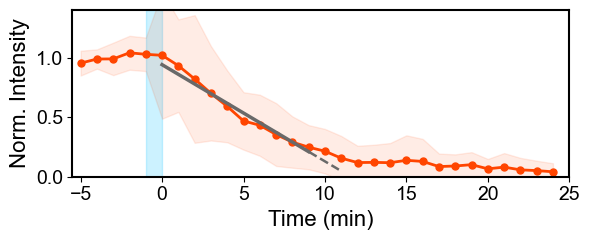

[UTag] ke = 2.99 aa/s (eff len=1765.5) | R2 = 0.9692 | t_runoff = 10.85 min
  Saved figure: /Users/nzlab-la/Desktop/utag_paper/notebooks/Figure_7_HT/figures_linear/Figure_7J_UTag_HT_linear.png
  Saved data:   /Users/nzlab-la/Desktop/utag_paper/notebooks/Figure_7_HT/raw_data_linear/Figure_7J_UTag_HT_linear_curves.csv


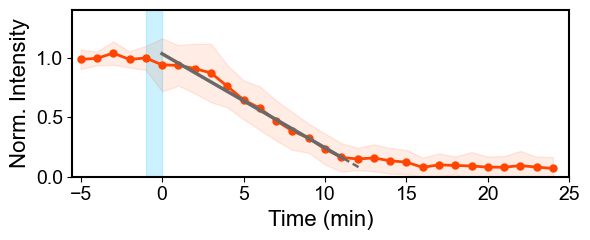

[UTag_C_Free] ke = 2.66 aa/s (eff len=1765.5) | R2 = 0.9791 | t_runoff = 12.06 min
  Saved figure: /Users/nzlab-la/Desktop/utag_paper/notebooks/Figure_7_HT/figures_linear/Figure_7K_UTag_DeltaCys_HT_linear.png
  Saved data:   /Users/nzlab-la/Desktop/utag_paper/notebooks/Figure_7_HT/raw_data_linear/Figure_7K_UTag_DeltaCys_HT_linear_curves.csv


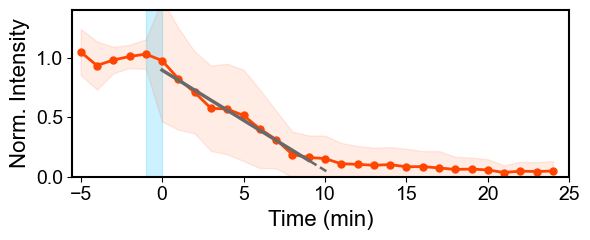

[SunTag] ke = 3.39 aa/s (eff len=1847.0) | R2 = 0.9760 | t_runoff = 10.09 min
  Saved figure: /Users/nzlab-la/Desktop/utag_paper/notebooks/Figure_7_HT/figures_linear/Figure_7L_SunTag_HT_linear.png
  Saved data:   /Users/nzlab-la/Desktop/utag_paper/notebooks/Figure_7_HT/raw_data_linear/Figure_7L_SunTag_HT_linear_curves.csv


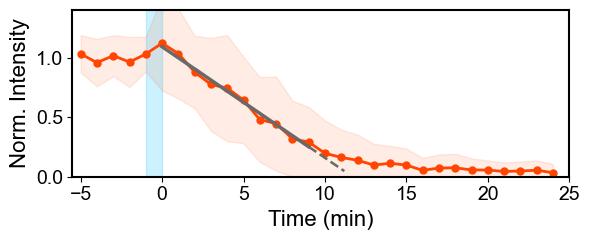

[AlfaTag] ke = 2.93 aa/s (eff len=1789.5) | R2 = 0.9864 | t_runoff = 11.19 min
  Saved figure: /Users/nzlab-la/Desktop/utag_paper/notebooks/Figure_7_HT/figures_linear/Figure_7M_ALFA_tag_HT_linear.png
  Saved data:   /Users/nzlab-la/Desktop/utag_paper/notebooks/Figure_7_HT/raw_data_linear/Figure_7M_ALFA_tag_HT_linear_curves.csv


In [68]:
# Selected optimal linear decay endpoints:
# Selected to capture the maximal active run-off window with highest R² before plateau
OPTIMAL_ENDPOINTS = {
    'utag': 14,        # t = 0 to 9 min (R² = 0.969)
    'utag_c_free': 16, # t = 0 to 11 min (R² = 0.979)
    'suntag': 14,      # t = 0 to 9 min (R² = 0.976)
    'alfatag': 14,     # t = 0 to 9 min (R² = 0.986)
}

linear_fit_results = {}

for dataset_name in list_datasets:
    data = dataset_data[dataset_name]
    plot_name = data['plot_name']
    eff_len = EFFECTIVE_GENE_LENGTHS[dataset_name]
    true_len = TRUE_GENE_LENGTHS[dataset_name]
    end_idx = OPTIMAL_ENDPOINTS[dataset_name]
    
    mean_traj = data['mean_trajectory']
    err_traj = data['std_trajectory']
    
    fit = fit_linear_decay(
        time_min, mean_traj, err_traj,
        fit_start_idx=harringtonine_frame, fit_end_idx=end_idx
    )
    ke = calculate_elongation_rate(fit['t_runoff'], eff_len, drug_entry_delay_seconds)
    fit['elongation_rate'] = ke
    linear_fit_results[dataset_name] = fit
    
    # ── Publication Plot Generation ───────────────────────────────────────
    fig, ax = plt.subplots(figsize=(6, 2.5), facecolor='white')
    ax.set_facecolor('white')
    
    # Experimental data with error band
    ax.plot(time_min, mean_traj, 'o-', color='orangered', linewidth=2,
            label='Experimental Data', markersize=5)
    ax.fill_between(time_min, mean_traj - err_traj, mean_traj + err_traj,
                    color='orangered', alpha=0.1)
    
    # Linear fit: solid line across the fit window
    fit_x_window = time_min[harringtonine_frame:end_idx + 1]
    fit_y_window = _linear_model(fit_x_window, fit['a'], fit['b'])
    ax.plot(fit_x_window, fit_y_window, '-', color='dimgray', linewidth=2.5,
            label=f'Linear Fit ({fit["t_start"]:.0f}–{fit["t_end"]:.0f} min)')
    
    # Dashed extrapolation line to run-off crossing
    extrap_x = np.linspace(fit['t_end'], fit['t_runoff'], 50)
    extrap_y = _linear_model(extrap_x, fit['a'], fit['b'])
    ax.plot(extrap_x, extrap_y, '--', color='dimgray', linewidth=1.8, label='Extrapolation')
    
    # Basal background level line
    #ax.axhline(fit['Iss'], color='gray', linestyle=':', linewidth=1.2, label=f'Basal ({fit["Iss"]:.2f})')
    
    # Harringtonine drug application window (-1 to 0 min)
    ax.axvspan(-1, 0, alpha=0.2, color='deepskyblue', zorder=0, label='HT Application')
    
    # Vertical dashed line at t_runoff
    # ax.axvline(fit['t_runoff'], color='purple', linestyle='--', linewidth=1.2,
    #            label=f't_runoff={fit["t_runoff"]:.1f} min')
    
    ax.set_xlabel("Time (min)", fontdict={'size': 16})
    ax.set_ylabel("Norm. Intensity", fontdict={'size': 16})
    ax.tick_params(axis='both', which='major', labelsize=14)
    
    for spine in ax.spines.values():
        spine.set_color('black')
        spine.set_linewidth(1.5)
        
    plt.ylim(0, 1.4)
    plt.xlim(-5.5, 25)
    ax.grid(False)
    
    # Annotate run-off time only
    # ax.text(
    #     0.96, 0.92,
    #     f"run-off = {fit['t_runoff']:.1f} min",
    #     transform=ax.transAxes,
    #     fontsize=13,
    #     verticalalignment='top',
    #     horizontalalignment='right',
    #     bbox=dict(boxstyle='round,pad=0.4', facecolor='white', edgecolor='lightgray', alpha=0.9)
    # )
    
    plt.tight_layout()
    
    # ── Export Source Data CSV ────────────────────────────────────────────
    figure_stem, source_csv_name = HT_PUBLICATION_INFO[dataset_name]
    
    # Build complete linear fit curve across all post-treatment timepoints
    linear_fit_curve = np.full_like(mean_traj, np.nan)
    linear_fit_curve[harringtonine_frame:] = _linear_model(time_min[harringtonine_frame:], fit['a'], fit['b'])
    
    source_dataframe = pd.DataFrame({
        'time_min': time_min,
        'mean_normalized_experimental_intensity': mean_traj,
        'population_sd_normalized_experimental_intensity': err_traj,
        'n_responding_cells': data['responding_cells'],
        'linear_fit_intensity': linear_fit_curve,
        'linear_fit_slope': fit['a'],
        'linear_fit_intercept': fit['b'],
        'linear_fit_r2': fit['r2'],
        'basal_intensity_Iss': fit['Iss'],
        't_runoff_min': fit['t_runoff'],
        't_half_min': fit['t_half'],
        'effective_gene_length_codons': eff_len,
        'true_gene_length_codons': true_len,
        'tag_region_size_codons': GENE_METRICS[dataset_name]['tag_region_size_codons'],
        'poi_size_codons': GENE_METRICS[dataset_name]['poi_size_codons'],
        'elongation_rate_aa_per_s': ke,
        'drug_entry_delay_seconds': drug_entry_delay_seconds,
    })
    
    source_csv_path = raw_data_linear_folder / source_csv_name
    source_dataframe.to_csv(source_csv_path, index=False)
    
    # ── Save Figures ──────────────────────────────────────────────────────
    fig_png_path = figures_linear_folder / f'{figure_stem}.png'
    fig_svg_path = figures_linear_folder / f'{figure_stem}.svg'
    plt.savefig(fig_png_path, dpi=600, bbox_inches='tight')
    plt.savefig(fig_svg_path, dpi=600, bbox_inches='tight', metadata={'Date': None})
    
    plt.show()
    print(f"[{plot_name}] ke = {ke:.2f} aa/s (eff len={eff_len:.1f}) | R2 = {fit['r2']:.4f} | t_runoff = {fit['t_runoff']:.2f} min")
    print(f"  Saved figure: {fig_png_path}")
    print(f"  Saved data:   {source_csv_path}")


In [66]:
# Non-parametric cell-level bootstrapping (2,000 replicates) using effective gene lengths
def bootstrap_ht_linear_fit(dataset_name, n_bootstrap=HT_BOOTSTRAP_REPLICATES):
    data = dataset_data[dataset_name]
    trajectories = data['intensities_responding']
    eff_len = EFFECTIVE_GENE_LENGTHS[dataset_name]
    end_idx = OPTIMAL_ENDPOINTS[dataset_name]
    n_cells = trajectories.shape[0]
    
    rng = np.random.default_rng(stable_seed(REPRODUCIBLE_RANDOM_SEED, dataset_name, 'linear_bootstrap'))
    records = []
    
    for rep in range(1, n_bootstrap + 1):
        # Resample cells with replacement
        sample_indices = rng.integers(0, n_cells, size=n_cells)
        sample_trajectories = trajectories[sample_indices, :]
        sample_mean = sample_trajectories.mean(axis=0)
        sample_std = sample_trajectories.std(axis=0)
        
        try:
            fit = fit_linear_decay(
                time_min, sample_mean, sample_std,
                fit_start_idx=harringtonine_frame, fit_end_idx=end_idx
            )
            ke_hat = calculate_elongation_rate(fit['t_runoff'], eff_len, drug_entry_delay_seconds)
            records.append({
                'dataset': dataset_name,
                'bootstrap_replicate': rep,
                'ke_hat_aa_per_s': ke_hat,
                't_runoff_hat_min': fit['t_runoff'],
                'slope_hat': fit['a'],
                'intercept_hat': fit['b'],
                'r2_hat': fit['r2'],
            })
        except Exception:
            continue
            
    return pd.DataFrame(records)

print("Running cell-level bootstrapping (2,000 replicates per dataset)...")
bootstrap_tables = []
summary_rows = []

for dataset_name in list_datasets:
    b_df = bootstrap_ht_linear_fit(dataset_name)
    bootstrap_tables.append(b_df)
    
    fit_orig = linear_fit_results[dataset_name]
    alpha = 1.0 - HT_BOOTSTRAP_INTERVAL_LEVEL
    
    ke_vals = b_df['ke_hat_aa_per_s'].dropna().to_numpy()
    low_ke, high_ke = np.quantile(ke_vals, [alpha / 2.0, 1.0 - alpha / 2.0], method='nearest')
    
    t_vals = b_df['t_runoff_hat_min'].dropna().to_numpy()
    low_t, high_t = np.quantile(t_vals, [alpha / 2.0, 1.0 - alpha / 2.0], method='nearest')
    
    summary_rows.append({
        'dataset': dataset_name,
        'construct': construct_labels[dataset_name],
        'ke_linear_fit_aa_per_s': fit_orig['elongation_rate'],
        'bootstrap_interval_level': HT_BOOTSTRAP_INTERVAL_LEVEL,
        'bootstrap_ke_low_aa_per_s': low_ke,
        'bootstrap_ke_high_aa_per_s': high_ke,
        'bootstrap_ke_median_aa_per_s': float(np.median(ke_vals)),
        't_runoff_min': fit_orig['t_runoff'],
        'bootstrap_t_runoff_low_min': low_t,
        'bootstrap_t_runoff_high_min': high_t,
        'slope_a': fit_orig['a'],
        'intercept_b': fit_orig['b'],
        'r2': fit_orig['r2'],
        'n_bootstrap_replicates': len(b_df),
        'n_total_cells': dataset_data[dataset_name]['total_cells'],
        'n_responding_cells': dataset_data[dataset_name]['responding_cells'],
        'effective_gene_length_codons': EFFECTIVE_GENE_LENGTHS[dataset_name],
        'true_gene_length_codons': TRUE_GENE_LENGTHS[dataset_name],
        'tag_region_size_codons': GENE_METRICS[dataset_name]['tag_region_size_codons'],
        'poi_size_codons': GENE_METRICS[dataset_name]['poi_size_codons'],
        'drug_entry_delay_seconds': drug_entry_delay_seconds,
        'fit_window_min': f"[{fit_orig['t_start']:.0f}, {fit_orig['t_end']:.0f}]",
    })

linear_summary_df = pd.DataFrame(summary_rows)
linear_bootstrap_df = pd.concat(bootstrap_tables, ignore_index=True)

summary_csv_path = linear_tables_folder / 'ht_linear_fit_summary_with_90pct_bootstrap.csv'
replicates_csv_path = linear_tables_folder / 'ht_linear_fit_bootstrap_replicates.csv'

linear_summary_df.to_csv(summary_csv_path, index=False)
linear_bootstrap_df.to_csv(replicates_csv_path, index=False)

print(f"\nSaved bootstrap summary:    {summary_csv_path}")
print(f"Saved bootstrap replicates: {replicates_csv_path}\n")

print("=== Harringtonine Linear Fit Elongation Rates (with Effective Gene Lengths & 90% Bootstrap CIs) ===")
display(linear_summary_df[[
    'construct', 'effective_gene_length_codons', 'ke_linear_fit_aa_per_s',
    'bootstrap_ke_low_aa_per_s', 'bootstrap_ke_high_aa_per_s',
    't_runoff_min', 'r2', 'n_responding_cells'
]])


Running cell-level bootstrapping (2,000 replicates per dataset)...

Saved bootstrap summary:    /Users/nzlab-la/Desktop/utag_paper/notebooks/Figure_7_HT/linear_fit_tables/ht_linear_fit_summary_with_90pct_bootstrap.csv
Saved bootstrap replicates: /Users/nzlab-la/Desktop/utag_paper/notebooks/Figure_7_HT/linear_fit_tables/ht_linear_fit_bootstrap_replicates.csv

=== Harringtonine Linear Fit Elongation Rates (with Effective Gene Lengths & 90% Bootstrap CIs) ===


,construct,effective_gene_length_codons,ke_linear_fit_aa_per_s,bootstrap_ke_low_aa_per_s,bootstrap_ke_high_aa_per_s,t_runoff_min,r2,n_responding_cells
0,Anti-UTag-IB,1765.5,2.985798,2.708799,3.242620,10.854987,0.969206,32
1,Anti-UTag-IB(ΔCys),1765.5,2.659950,2.537320,2.785548,12.062239,0.979132,22
2,Anti-SunTag-IB,1847.0,3.387966,3.131447,3.633203,10.086082,0.976021,32
3,Anti-ALFA-IB,1789.5,2.926449,2.608438,3.219317,11.191532,0.986358,32


In [67]:
# Load original TASEP simulation optimization results for direct comparison
sim_summary_path = figure_7_dir / 'optimization_tables' / 'ht_ke_optimization_with_90pct_bootstrap_ranges.csv'
if sim_summary_path.exists():
    sim_df = pd.read_csv(sim_summary_path)
    
    comp_df = pd.DataFrame({
        'construct': linear_summary_df['construct'],
        'dataset': linear_summary_df['dataset'],
        'effective_gene_length_codons': linear_summary_df['effective_gene_length_codons'],
        'linear_fit_ke_aa_per_s': linear_summary_df['ke_linear_fit_aa_per_s'].round(2),
        'linear_fit_90ci': [f"[{row['bootstrap_ke_low_aa_per_s']:.2f}, {row['bootstrap_ke_high_aa_per_s']:.2f}]" for _, row in linear_summary_df.iterrows()],
        'tasep_simulation_ke_aa_per_s': sim_df['ke_optimized_aa_per_s'].round(2),
        'tasep_simulation_90ci': [f"[{row['bootstrap_range_low_aa_per_s']:.2f}, {row['bootstrap_range_high_aa_per_s']:.2f}]" for _, row in sim_df.iterrows()],
        'difference_aa_per_s': (linear_summary_df['ke_linear_fit_aa_per_s'] - sim_df['ke_optimized_aa_per_s']).round(2),
        'pct_difference': (((linear_summary_df['ke_linear_fit_aa_per_s'] - sim_df['ke_optimized_aa_per_s']) / sim_df['ke_optimized_aa_per_s']) * 100).round(1),
    })
    
    comp_csv_path = linear_tables_folder / 'elongation_rate_comparison_linear_vs_simulation.csv'
    comp_df.to_csv(comp_csv_path, index=False)
    
    print("=== Direct Method Comparison: Linear Fit vs. TASEP Kinetic Simulation ===")
    display(comp_df[[
        'construct', 'effective_gene_length_codons', 'linear_fit_ke_aa_per_s', 'linear_fit_90ci',
        'tasep_simulation_ke_aa_per_s', 'tasep_simulation_90ci',
        'difference_aa_per_s', 'pct_difference'
    ]])
    print(f"Saved method comparison: {comp_csv_path}")
else:
    print(f"Original simulation table not found at {sim_summary_path}; skipping merged table.")


=== Direct Method Comparison: Linear Fit vs. TASEP Kinetic Simulation ===


,construct,effective_gene_length_codons,linear_fit_ke_aa_per_s,linear_fit_90ci,tasep_simulation_ke_aa_per_s,tasep_simulation_90ci,difference_aa_per_s,pct_difference
0,Anti-UTag-IB,1765.5,2.99,"[2.71, 3.24]",3.3,"[3.30, 4.50]",-0.31,-9.5
1,Anti-UTag-IB(ΔCys),1765.5,2.66,"[2.54, 2.79]",3.0,"[2.90, 3.00]",-0.34,-11.3
2,Anti-SunTag-IB,1847.0,3.39,"[3.13, 3.63]",4.5,"[3.80, 5.60]",-1.11,-24.7
3,Anti-ALFA-IB,1789.5,2.93,"[2.61, 3.22]",3.3,"[2.60, 3.80]",-0.37,-11.3


Saved method comparison: /Users/nzlab-la/Desktop/utag_paper/notebooks/Figure_7_HT/linear_fit_tables/elongation_rate_comparison_linear_vs_simulation.csv
